PROVISIONAL H0(z_d) ANALYSIS
Number of observations: 11
Deflector redshift range: 0.230 to 0.745

LINEAR MODEL: H0 = a + b*z_d
Intercept a = 83.653 km/s/Mpc
Slope b     = -19.526 km/s/Mpc per unit redshift
Nominal 95% profile-likelihood interval for b: [-37.424, -1.719]

CONSTANT MODEL: H0 = c
Constant c = 73.032 km/s/Mpc

MODEL COMPARISON
log L (linear)    = -29.905
log L (constant)  = -32.217
AIC (linear)      = 63.810
AIC (constant)    = 66.435
AICc (linear)     = 65.310
AICc (constant)   = 66.879
Delta AIC         = 2.625
Delta AICc        = 1.569

LEAVE-ONE-LENS-OUT SLOPES
Remove point  1 (z_d=0.230): slope = -20.233
Remove point  2 (z_d=0.295): slope = -18.200
Remove point  3 (z_d=0.311): slope = -18.001
Remove point  4 (z_d=0.407): slope = -20.938
Remove point  5 (z_d=0.454): slope = -20.605
Remove point  6 (z_d=0.590): slope = -19.961
Remove point  7 (z_d=0.597): slope = -21.060
Remove point  8 (z_d=0.630): slope = -19.083
Remove point  9 (z_d=0.657): slope = -19.884
Remove poi

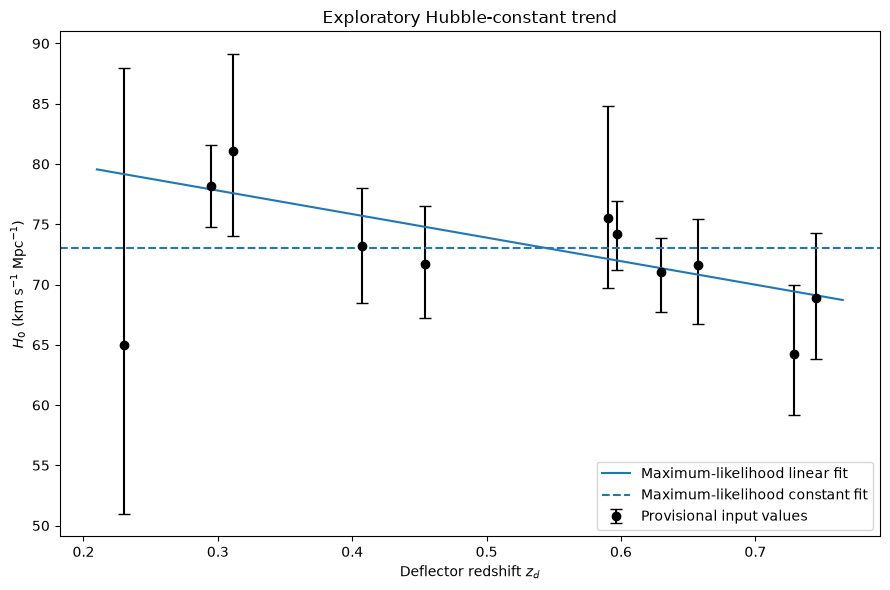

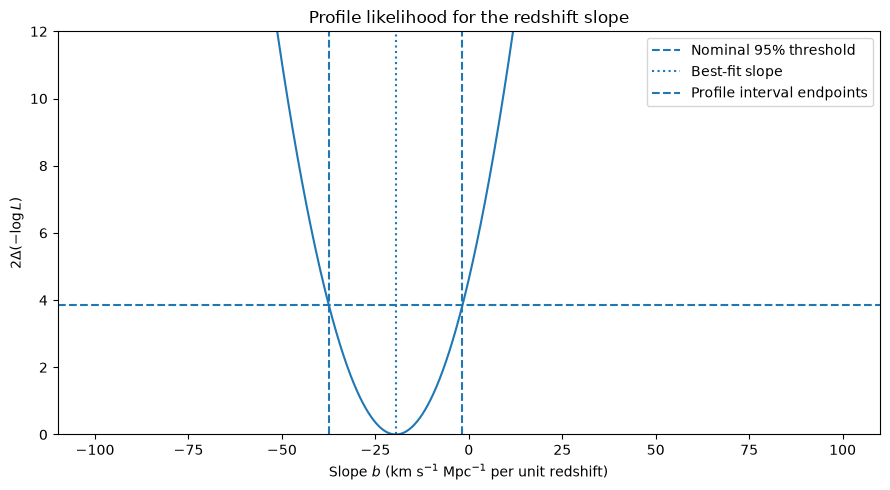

In [1]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize, minimize_scalar, brentq
from scipy.stats import chi2

# ============================================================
# TDCOSMO H0 versus deflector redshift: provisional analysis
# ============================================================

z = np.array([
    0.230, 0.295, 0.311, 0.407, 0.454, 0.590,
    0.597, 0.630, 0.657, 0.729, 0.745
])

H0 = np.array([
    65.0, 78.2, 81.1, 73.2, 71.7, 75.5,
    74.2, 71.0, 71.6, 64.2, 68.9
])

sigma_minus = np.array([
    14.0, 3.4, 7.1, 4.7, 4.5, 5.8,
    3.0, 3.3, 4.9, 5.0, 5.1
])

sigma_plus = np.array([
    23.0, 3.4, 8.0, 4.8, 4.8, 9.3,
    2.7, 2.9, 3.8, 5.8, 5.4
])

n = len(z)

assert len(H0) == len(sigma_minus) == len(sigma_plus) == n
assert np.all(sigma_minus > 0)
assert np.all(sigma_plus > 0)

# ------------------------------------------------------------
# 1. Split-normal negative log-likelihood
#
# residual = observed H0 - predicted H0
#
# residual > 0: observed value is above prediction;
#               prediction is on the lower side, so use
#               sigma_minus.
#
# residual < 0: observed value is below prediction;
#               prediction is on the upper side, so use
#               sigma_plus.
#
# The split-normal normalization is included.
# ------------------------------------------------------------

def negative_log_likelihood(theta, model="linear", mask=None):

    if model == "linear":
        a, b = theta
        prediction = a + b * z

    elif model == "constant":
        a = theta[0]
        prediction = np.full(n, a)

    else:
        raise ValueError("model must be 'linear' or 'constant'")

    residual = H0 - prediction

    # Correct asymmetric uncertainty assignment
    sigma = np.where(
        residual >= 0,
        sigma_minus,
        sigma_plus
    )

    terms = (
        0.5 * (residual / sigma)**2
        + np.log(sigma_minus + sigma_plus)
        - 0.5 * np.log(2.0 / np.pi)
    )

    if mask is not None:
        terms = terms[mask]

    return np.sum(terms)


# ------------------------------------------------------------
# 2. Maximum-likelihood fits
# ------------------------------------------------------------

fit_linear = minimize(
    negative_log_likelihood,
    x0=[83.0, -15.0],
    args=("linear",),
    method="Nelder-Mead",
    options={"maxiter": 100000, "xatol": 1e-10, "fatol": 1e-10}
)

fit_constant = minimize(
    negative_log_likelihood,
    x0=[73.0],
    args=("constant",),
    method="Nelder-Mead",
    options={"maxiter": 100000, "xatol": 1e-10, "fatol": 1e-10}
)

if not fit_linear.success:
    raise RuntimeError(f"Linear fit failed: {fit_linear.message}")

if not fit_constant.success:
    raise RuntimeError(f"Constant fit failed: {fit_constant.message}")

a_hat, b_hat = fit_linear.x
c_hat = fit_constant.x[0]

nll_linear = fit_linear.fun
nll_constant = fit_constant.fun

logL_linear = -nll_linear
logL_constant = -nll_constant


# ------------------------------------------------------------
# 3. AIC and AICc
# ------------------------------------------------------------

def calculate_aic(nll, k, n_data):

    aic = 2 * k + 2 * nll

    if n_data <= k + 1:
        aicc = np.inf
    else:
        aicc = aic + 2 * k * (k + 1) / (n_data - k - 1)

    return aic, aicc


aic_linear, aicc_linear = calculate_aic(nll_linear, 2, n)
aic_constant, aicc_constant = calculate_aic(nll_constant, 1, n)

# Positive delta means the linear model has the lower criterion
delta_aic = aic_constant - aic_linear
delta_aicc = aicc_constant - aicc_linear


# ------------------------------------------------------------
# 4. Profile-likelihood interval for the slope
#
# At each fixed slope b, optimize over intercept a.
# The nominal 95% likelihood-ratio threshold is:
#
# 2 * Delta NLL = chi2.ppf(0.95, df=1)
#
# The interval is approximate and relies on asymptotic
# likelihood-ratio assumptions.
# ------------------------------------------------------------

def profile_nll_for_slope(b):

    result = minimize_scalar(
        lambda a: negative_log_likelihood([a, b], model="linear"),
        bounds=(20.0, 140.0),
        method="bounded",
        options={"xatol": 1e-10}
    )

    if not result.success:
        raise RuntimeError(
            f"Intercept optimization failed at slope {b}: "
            f"{result.message}"
        )

    return result.fun


threshold = nll_linear + 0.5 * chi2.ppf(0.95, df=1)

# Wide grid used to find the profile interval and plot the curve
slope_grid = np.linspace(-100.0, 100.0, 4001)

profile_values = np.array([
    profile_nll_for_slope(b) for b in slope_grid
])

profile_delta = profile_values - nll_linear

# Find crossings of profile NLL with the 95% threshold.
# First identify the connected region containing the best fit.
inside = profile_delta <= (threshold - nll_linear)

best_index = np.argmin(profile_values)

if not inside[best_index]:
    raise RuntimeError(
        "The best-fit slope is not inside the profile interval."
    )

left_index = best_index
while left_index > 0 and inside[left_index - 1]:
    left_index -= 1

right_index = best_index
while (
    right_index < len(slope_grid) - 1
    and inside[right_index + 1]
):
    right_index += 1

if left_index == 0 or right_index == len(slope_grid) - 1:
    slope_low = np.nan
    slope_high = np.nan
    print(
        "Warning: profile interval reaches the slope-grid boundary. "
        "Expand slope_grid and rerun."
    )
else:
    target = 0.5 * chi2.ppf(0.95, df=1)

    slope_low = brentq(
        lambda b: profile_nll_for_slope(b) - nll_linear - target,
        slope_grid[left_index - 1],
        slope_grid[left_index]
    )

    slope_high = brentq(
        lambda b: profile_nll_for_slope(b) - nll_linear - target,
        slope_grid[right_index],
        slope_grid[right_index + 1]
    )


# ------------------------------------------------------------
# 5. Leave-one-lens-out sensitivity
# ------------------------------------------------------------

loo_slopes = []
loo_success = []

for i in range(n):

    mask = np.ones(n, dtype=bool)
    mask[i] = False

    result = minimize(
        negative_log_likelihood,
        x0=fit_linear.x,
        args=("linear", mask),
        method="Nelder-Mead",
        options={
            "maxiter": 100000,
            "xatol": 1e-10,
            "fatol": 1e-10
        }
    )

    if not result.success:
        raise RuntimeError(
            f"Leave-one-out fit failed when removing point {i+1}: "
            f"{result.message}"
        )

    loo_slopes.append(result.x[1])
    loo_success.append(result.success)

loo_slopes = np.array(loo_slopes)


# ------------------------------------------------------------
# 6. Print results
# ------------------------------------------------------------

print("=" * 65)
print("PROVISIONAL H0(z_d) ANALYSIS")
print("=" * 65)

print(f"Number of observations: {n}")
print(f"Deflector redshift range: {z.min():.3f} to {z.max():.3f}")
print()

print("LINEAR MODEL: H0 = a + b*z_d")
print(f"Intercept a = {a_hat:.3f} km/s/Mpc")
print(f"Slope b     = {b_hat:.3f} km/s/Mpc per unit redshift")

if np.isfinite(slope_low) and np.isfinite(slope_high):
    print(
        "Nominal 95% profile-likelihood interval for b: "
        f"[{slope_low:.3f}, {slope_high:.3f}]"
    )
else:
    print("95% profile-likelihood interval could not be bounded.")

print()

print("CONSTANT MODEL: H0 = c")
print(f"Constant c = {c_hat:.3f} km/s/Mpc")
print()

print("MODEL COMPARISON")
print(f"log L (linear)    = {logL_linear:.3f}")
print(f"log L (constant)  = {logL_constant:.3f}")
print(f"AIC (linear)      = {aic_linear:.3f}")
print(f"AIC (constant)    = {aic_constant:.3f}")
print(f"AICc (linear)     = {aicc_linear:.3f}")
print(f"AICc (constant)   = {aicc_constant:.3f}")
print(f"Delta AIC         = {delta_aic:.3f}")
print(f"Delta AICc        = {delta_aicc:.3f}")
print()

print("LEAVE-ONE-LENS-OUT SLOPES")

for i, slope in enumerate(loo_slopes):
    print(
        f"Remove point {i+1:2d} (z_d={z[i]:.3f}): "
        f"slope = {slope:.3f}"
    )

print()
print(
    f"LOO slope range: {loo_slopes.min():.3f} to "
    f"{loo_slopes.max():.3f}"
)

print()
print("Interpretation reminder:")
print("- Positive Delta AIC/AICc favors the linear model.")
print("- Small differences indicate weak model preference.")
print("- This is an exploratory fit, not a hierarchical TDCOSMO result.")


# ------------------------------------------------------------
# 7. Plot data and fitted models
# ------------------------------------------------------------

z_grid = np.linspace(z.min() - 0.02, z.max() + 0.02, 300)

plt.figure(figsize=(9, 6))

plt.errorbar(
    z,
    H0,
    yerr=[sigma_minus, sigma_plus],
    fmt="o",
    capsize=4,
    color="black",
    label="Provisional input values"
)

plt.plot(
    z_grid,
    a_hat + b_hat * z_grid,
    label="Maximum-likelihood linear fit"
)

plt.axhline(
    c_hat,
    linestyle="--",
    label="Maximum-likelihood constant fit"
)

plt.xlabel(r"Deflector redshift $z_d$")
plt.ylabel(r"$H_0$ (km s$^{-1}$ Mpc$^{-1}$)")
plt.title("Exploratory Hubble-constant trend")
plt.legend()
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 8. Plot profile likelihood for the slope
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

two_delta_nll = 2.0 * (profile_values - nll_linear)

plt.plot(slope_grid, two_delta_nll)

plt.axhline(
    chi2.ppf(0.95, df=1),
    linestyle="--",
    label="Nominal 95% threshold"
)

plt.axvline(
    b_hat,
    linestyle=":",
    label="Best-fit slope"
)

if np.isfinite(slope_low):
    plt.axvline(
        slope_low,
        linestyle="--",
        label="Profile interval endpoints"
    )
    plt.axvline(
        slope_high,
        linestyle="--"
    )

plt.xlabel(r"Slope $b$ (km s$^{-1}$ Mpc$^{-1}$ per unit redshift)")
plt.ylabel(r"$2\Delta(-\log L)$")
plt.title("Profile likelihood for the redshift slope")
plt.ylim(0, 12)
plt.legend()
plt.tight_layout()
plt.show()


EXPLORATORY H0(z_d) ANALYSIS
Number of observations: 11
Redshift range: 0.230 to 0.745

SPLIT-NORMAL LINEAR MODEL: H0 = a + b*z
Intercept a = 83.653 km/s/Mpc
Slope b = -19.526 km/s/Mpc per unit redshift
Predicted H0 at mean redshift = 73.633 km/s/Mpc
Nominal 95% profile interval for slope: [-37.424, -1.719]

CONSTANT MODEL
Constant H0 = 73.032 km/s/Mpc

MODEL COMPARISON
Linear NLL = 29.905
Constant NLL = 32.217
AIC linear = 63.810
AIC constant = 66.435
AICc linear = 65.310
AICc constant = 66.879
Delta AIC (constant - linear) = 2.625
Delta AICc (constant - linear) = 1.569

OPTIMIZER STABILITY
Successful linear starts: 4 / 4
Successful constant starts: 3 / 3
Spread in successful linear-fit NLLs: 0.000e+00

LEAVE-ONE-LENS-OUT SLOPES
Exclude z=0.230: slope=-20.233 km/s/Mpc per unit redshift
Exclude z=0.295: slope=-18.200 km/s/Mpc per unit redshift
Exclude z=0.311: slope=-18.001 km/s/Mpc per unit redshift
Exclude z=0.407: slope=-20.938 km/s/Mpc per unit redshift
Exclude z=0.454: slope=-20.6

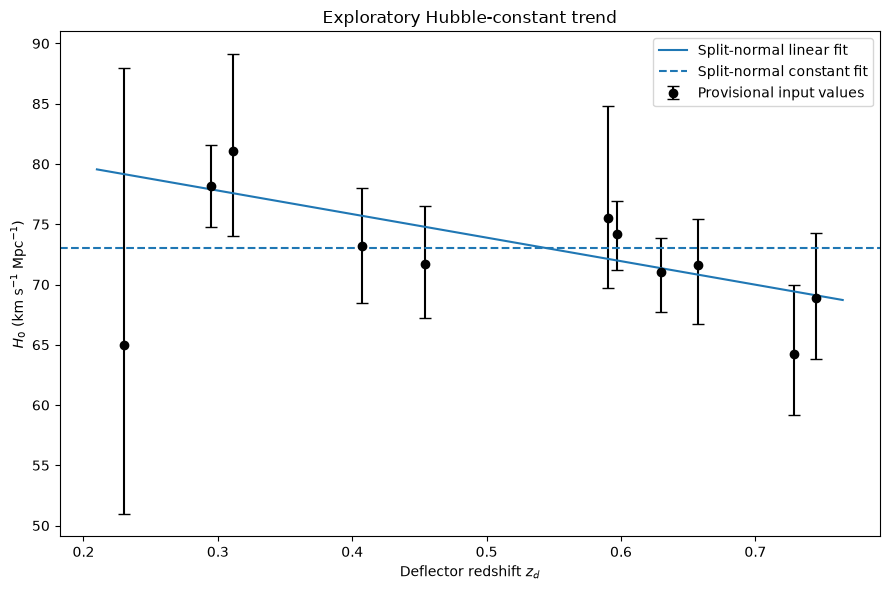

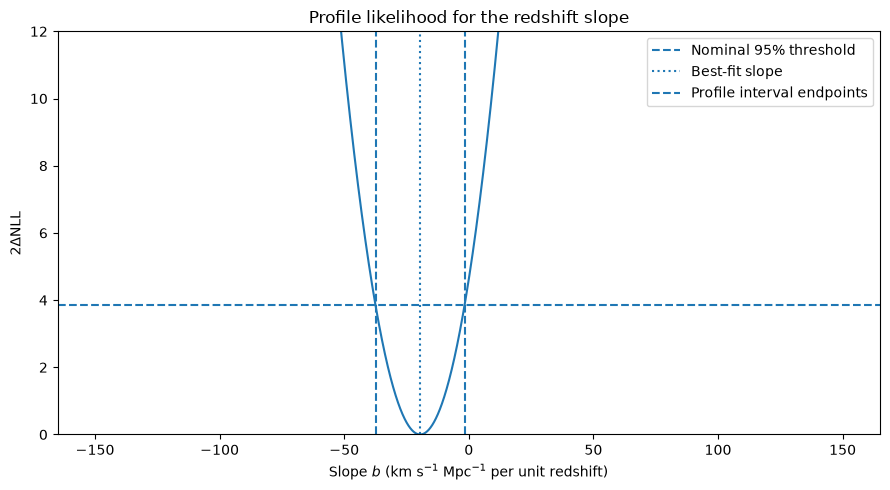

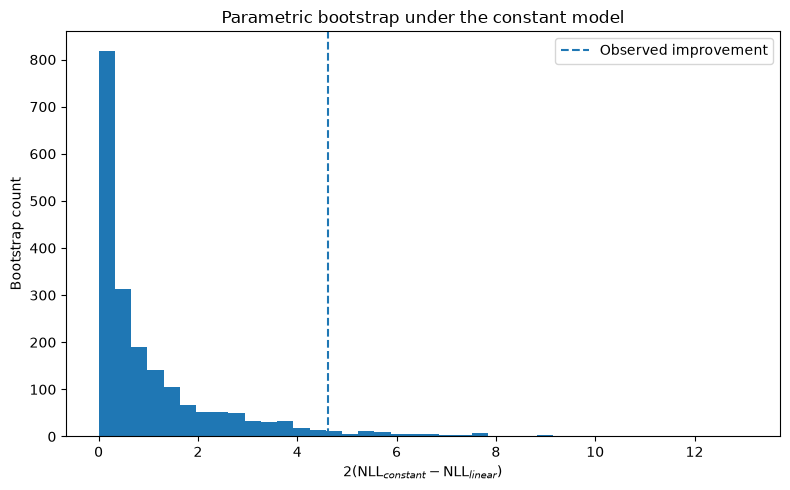

In [2]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize, minimize_scalar, brentq
from scipy.stats import chi2

# ============================================================
# EXPLORATORY ANALYSIS: H0 VERSUS DEFLECTOR REDSHIFT
# ============================================================
# This is a phenomenological analysis of provisional published
# measurements, NOT the full hierarchical TDCOSMO likelihood.
# ============================================================

z = np.array([
    0.230, 0.295, 0.311, 0.407, 0.454, 0.590,
    0.597, 0.630, 0.657, 0.729, 0.745
], dtype=float)

H0 = np.array([
    65.0, 78.2, 81.1, 73.2, 71.7, 75.5,
    74.2, 71.0, 71.6, 64.2, 68.9
], dtype=float)

sigma_minus = np.array([
    14.0, 3.4, 7.1, 4.7, 4.5, 5.8,
    3.0, 3.3, 4.9, 5.0, 5.1
], dtype=float)

sigma_plus = np.array([
    23.0, 3.4, 8.0, 4.8, 4.8, 9.3,
    2.7, 2.9, 3.8, 5.8, 5.4
], dtype=float)

n = len(z)

assert len(H0) == len(sigma_minus) == len(sigma_plus) == n
assert np.all(sigma_minus > 0)
assert np.all(sigma_plus > 0)

# Centre redshift to improve numerical conditioning.
z_ref = np.mean(z)
x = z - z_ref


# ============================================================
# 1. SPLIT-NORMAL NEGATIVE LOG-LIKELIHOOD
# ============================================================
# residual = observed value - model prediction
#
# residual >= 0: prediction is below the measured central value;
#                use sigma_minus.
# residual < 0:  prediction is above the measured central value;
#                use sigma_plus.
#
# Include the split-normal normalization.
# ============================================================

def nll(theta, model="linear", mask=None, y_override=None):

    y = H0 if y_override is None else np.asarray(y_override)

    if model == "linear":
        h_ref, slope = theta
        prediction = h_ref + slope * x

    elif model == "constant":
        prediction = np.full(n, theta[0], dtype=float)

    else:
        raise ValueError("model must be 'linear' or 'constant'")

    residual = y - prediction

    # Correct assignment of asymmetric uncertainties.
    sigma = np.where(
        residual >= 0,
        sigma_minus,
        sigma_plus
    )

    terms = (
        0.5 * (residual / sigma)**2
        + np.log(sigma_minus + sigma_plus)
        - 0.5 * np.log(2.0 / np.pi)
    )

    if mask is not None:
        terms = terms[mask]

    return float(np.sum(terms))


# ============================================================
# 2. MULTI-START MAXIMUM-LIKELIHOOD FITS
# ============================================================

def fit_model(model, mask=None, y_override=None):

    if model == "linear":
        starts = [
            [73.0, 0.0],
            [80.0, -20.0],
            [65.0, 20.0],
            [75.0, -50.0]
        ]
    else:
        starts = [
            [70.0],
            [75.0],
            [80.0]
        ]

    results = []

    for start in starts:
        result = minimize(
            nll,
            x0=np.array(start, dtype=float),
            args=(model, mask, y_override),
            method="Nelder-Mead",
            options={
                "maxiter": 100000,
                "xatol": 1e-9,
                "fatol": 1e-9
            }
        )

        if result.success and np.isfinite(result.fun):
            results.append(result)

    if not results:
        raise RuntimeError(
            f"All optimizer starts failed for the {model} model."
        )

    best = min(results, key=lambda result: result.fun)

    return best, results


fit_linear, linear_starts = fit_model("linear")
fit_constant, constant_starts = fit_model("constant")

h_ref, slope = fit_linear.x
constant = fit_constant.x[0]

nll_linear = fit_linear.fun
nll_constant = fit_constant.fun

# Convert H0 = h_ref + slope*(z - z_ref) to H0 = a + b*z.
b = slope
a = h_ref - slope * z_ref


# ============================================================
# 3. AIC AND AICc
# ============================================================

def calculate_aic_aicc(nll_value, k, n_data):

    aic = 2 * k + 2 * nll_value

    if n_data <= k + 1:
        aicc = np.inf
    else:
        aicc = aic + 2 * k * (k + 1) / (n_data - k - 1)

    return aic, aicc


aic_linear, aicc_linear = calculate_aic_aicc(
    nll_linear, k=2, n_data=n
)

aic_constant, aicc_constant = calculate_aic_aicc(
    nll_constant, k=1, n_data=n
)

# Positive values favour the linear model.
delta_aic = aic_constant - aic_linear
delta_aicc = aicc_constant - aicc_linear


# ============================================================
# 4. PROFILE-LIKELIHOOD INTERVAL FOR THE SLOPE
# ============================================================

def profile_nll(slope_fixed):

    result = minimize_scalar(
        lambda h: nll([h, slope_fixed], model="linear"),
        bounds=(20.0, 140.0),
        method="bounded",
        options={"xatol": 1e-10}
    )

    if not result.success:
        raise RuntimeError(
            f"Profile optimization failed at slope {slope_fixed}."
        )

    return result.fun


lr_threshold = chi2.ppf(0.95, df=1)
target_nll = nll_linear + 0.5 * lr_threshold

slope_grid = np.linspace(-150.0, 150.0, 6001)

profile_values = np.array([
    profile_nll(value) for value in slope_grid
])

profile_lr = 2.0 * (profile_values - nll_linear)

best_index = int(np.argmin(profile_values))
inside = profile_lr <= lr_threshold

left_index = best_index

while left_index > 0 and inside[left_index - 1]:
    left_index -= 1

right_index = best_index

while (
    right_index < len(slope_grid) - 1
    and inside[right_index + 1]
):
    right_index += 1

if left_index == 0 or right_index == len(slope_grid) - 1:

    slope_low = np.nan
    slope_high = np.nan

    print(
        "WARNING: profile interval reaches the grid boundary. "
        "Expand slope_grid."
    )

else:

    slope_low = brentq(
        lambda value: profile_nll(value) - target_nll,
        slope_grid[left_index - 1],
        slope_grid[left_index]
    )

    slope_high = brentq(
        lambda value: profile_nll(value) - target_nll,
        slope_grid[right_index],
        slope_grid[right_index + 1]
    )


# ============================================================
# 5. LEAVE-ONE-LENS-OUT SENSITIVITY
# ============================================================

loo_slopes = []

for i in range(n):

    mask = np.ones(n, dtype=bool)
    mask[i] = False

    result, _ = fit_model(
        "linear",
        mask=mask
    )

    loo_slopes.append(result.x[1])

loo_slopes = np.asarray(loo_slopes)


# ============================================================
# 6. SENSITIVITY CHECK USING SYMMETRIC ERRORS
# ============================================================
# Replace each asymmetric error pair with its average.
# This is a diagnostic comparison, not the primary likelihood.
# ============================================================

sigma_symmetric = 0.5 * (sigma_minus + sigma_plus)


def gaussian_nll(theta, model="linear"):

    if model == "linear":
        h_ref_fit, slope_fit = theta
        prediction = h_ref_fit + slope_fit * x

    else:
        prediction = np.full(n, theta[0], dtype=float)

    residual = H0 - prediction

    terms = (
        0.5 * (residual / sigma_symmetric)**2
        + np.log(sigma_symmetric)
    )

    return float(np.sum(terms))


def fit_symmetric_model(model):

    if model == "linear":
        starts = [
            [73.0, 0.0],
            [80.0, -20.0],
            [65.0, 20.0]
        ]
    else:
        starts = [[70.0], [75.0], [80.0]]

    results = []

    for start in starts:
        result = minimize(
            gaussian_nll,
            x0=np.array(start, dtype=float),
            args=(model,),
            method="Nelder-Mead",
            options={
                "maxiter": 100000,
                "xatol": 1e-9,
                "fatol": 1e-9
            }
        )

        if result.success and np.isfinite(result.fun):
            results.append(result)

    if not results:
        raise RuntimeError(
            f"Symmetric-error fit failed for {model} model."
        )

    return min(results, key=lambda result: result.fun)


symmetric_linear = fit_symmetric_model("linear")
symmetric_constant = fit_symmetric_model("constant")


# ============================================================
# 7. PARAMETRIC BOOTSTRAP UNDER THE CONSTANT MODEL
# ============================================================
# Simulate datasets under the fitted constant model, refit the
# constant and linear models, and compare their likelihood gains.
#
# This tests the assumed statistical model only. It does not
# account for cross-paper systematics or correlated errors.
# ============================================================

rng = np.random.default_rng(20261022)

B = 2000  # Use B = 200 for a quick test run.

def draw_split_normal(center, s_minus, s_plus, rng):

    # For this split-normal parameterization, the probability
    # of drawing on each side is proportional to that side's
    # scale parameter.
    choose_minus = (
        rng.random(len(center)) < s_minus / (s_minus + s_plus)
    )

    magnitude = np.abs(rng.normal(size=len(center)))

    simulated = np.empty(len(center))

    simulated[choose_minus] = (
        center[choose_minus]
        - s_minus[choose_minus] * magnitude[choose_minus]
    )

    simulated[~choose_minus] = (
        center[~choose_minus]
        + s_plus[~choose_minus] * magnitude[~choose_minus]
    )

    return simulated


null_center = np.full(n, constant)

observed_improvement = 2.0 * (
    nll_constant - nll_linear
)

bootstrap_improvements = np.empty(B)

for j in range(B):

    simulated_H0 = draw_split_normal(
        null_center,
        sigma_minus,
        sigma_plus,
        rng
    )

    simulated_linear, _ = fit_model(
        "linear",
        y_override=simulated_H0
    )

    simulated_constant, _ = fit_model(
        "constant",
        y_override=simulated_H0
    )

    bootstrap_improvements[j] = 2.0 * (
        simulated_constant.fun - simulated_linear.fun
    )

# Add-one correction avoids reporting a zero Monte Carlo p-value.
bootstrap_p = (
    1 + np.sum(bootstrap_improvements >= observed_improvement)
) / (B + 1)


# ============================================================
# 8. PRINT RESULTS
# ============================================================

print("=" * 70)
print("EXPLORATORY H0(z_d) ANALYSIS")
print("=" * 70)

print(f"Number of observations: {n}")
print(f"Redshift range: {z.min():.3f} to {z.max():.3f}")
print()

print("SPLIT-NORMAL LINEAR MODEL: H0 = a + b*z")
print(f"Intercept a = {a:.3f} km/s/Mpc")
print(f"Slope b = {b:.3f} km/s/Mpc per unit redshift")
print(f"Predicted H0 at mean redshift = {h_ref:.3f} km/s/Mpc")

if np.isfinite(slope_low) and np.isfinite(slope_high):
    print(
        "Nominal 95% profile interval for slope: "
        f"[{slope_low:.3f}, {slope_high:.3f}]"
    )
else:
    print("Profile interval could not be bounded.")

print()
print("CONSTANT MODEL")
print(f"Constant H0 = {constant:.3f} km/s/Mpc")
print()

print("MODEL COMPARISON")
print(f"Linear NLL = {nll_linear:.3f}")
print(f"Constant NLL = {nll_constant:.3f}")
print(f"AIC linear = {aic_linear:.3f}")
print(f"AIC constant = {aic_constant:.3f}")
print(f"AICc linear = {aicc_linear:.3f}")
print(f"AICc constant = {aicc_constant:.3f}")
print(f"Delta AIC (constant - linear) = {delta_aic:.3f}")
print(f"Delta AICc (constant - linear) = {delta_aicc:.3f}")
print()

print("OPTIMIZER STABILITY")
print(f"Successful linear starts: {len(linear_starts)} / 4")
print(f"Successful constant starts: {len(constant_starts)} / 3")

linear_nll_spread = (
    max(result.fun for result in linear_starts)
    - min(result.fun for result in linear_starts)
)

print(f"Spread in successful linear-fit NLLs: {linear_nll_spread:.3e}")
print()

print("LEAVE-ONE-LENS-OUT SLOPES")

for i, value in enumerate(loo_slopes):
    print(
        f"Exclude z={z[i]:.3f}: "
        f"slope={value:.3f} km/s/Mpc per unit redshift"
    )

print(
    f"LOO slope range: {loo_slopes.min():.3f} to "
    f"{loo_slopes.max():.3f}"
)
print()

print("SYMMETRIC-ERROR SENSITIVITY CHECK")
print(
    "Symmetric-error slope = "
    f"{symmetric_linear.x[1]:.3f} km/s/Mpc per unit redshift"
)
print(
    "Symmetric-error constant H0 = "
    f"{symmetric_constant.x[0]:.3f} km/s/Mpc"
)
print()

print("PARAMETRIC BOOTSTRAP UNDER THE CONSTANT MODEL")
print(f"Bootstrap simulations: {B}")
print(f"Observed 2*Delta log L improvement: {observed_improvement:.3f}")
print(f"Approximate bootstrap tail fraction: {bootstrap_p:.4f}")
print()
print("INTERPRETATION")
print("- Positive Delta AIC/AICc favours the linear model.")
print("- Small AICc differences indicate weak model preference.")
print("- The bootstrap result is conditional on this likelihood.")
print("- These fits do not establish physical evolution of H0.")
print("- The estimates' source papers and assumptions need validation.")


# ============================================================
# 9. PLOT THE DATA AND FITTED MODELS
# ============================================================

z_plot = np.linspace(z.min() - 0.02, z.max() + 0.02, 300)
x_plot = z_plot - z_ref

plt.figure(figsize=(9, 6))

plt.errorbar(
    z,
    H0,
    yerr=[sigma_minus, sigma_plus],
    fmt="o",
    capsize=4,
    color="black",
    label="Provisional input values"
)

plt.plot(
    z_plot,
    h_ref + slope * x_plot,
    label="Split-normal linear fit"
)

plt.axhline(
    constant,
    linestyle="--",
    label="Split-normal constant fit"
)

plt.xlabel(r"Deflector redshift $z_d$")
plt.ylabel(r"$H_0$ (km s$^{-1}$ Mpc$^{-1}$)")
plt.title("Exploratory Hubble-constant trend")
plt.legend()
plt.tight_layout()
plt.show()


# ============================================================
# 10. PLOT THE PROFILE LIKELIHOOD
# ============================================================

plt.figure(figsize=(9, 5))

plt.plot(slope_grid, profile_lr)

plt.axhline(
    lr_threshold,
    linestyle="--",
    label="Nominal 95% threshold"
)

plt.axvline(
    slope,
    linestyle=":",
    label="Best-fit slope"
)

if np.isfinite(slope_low) and np.isfinite(slope_high):
    plt.axvline(
        slope_low,
        linestyle="--",
        label="Profile interval endpoints"
    )
    plt.axvline(slope_high, linestyle="--")

plt.xlabel(
    r"Slope $b$ (km s$^{-1}$ Mpc$^{-1}$ per unit redshift)"
)
plt.ylabel(r"$2\Delta\mathrm{NLL}$")
plt.title("Profile likelihood for the redshift slope")
plt.ylim(0, 12)
plt.legend()
plt.tight_layout()
plt.show()


# ============================================================
# 11. PLOT THE BOOTSTRAP DISTRIBUTION
# ============================================================

plt.figure(figsize=(8, 5))

plt.hist(
    bootstrap_improvements,
    bins=40
)

plt.axvline(
    observed_improvement,
    linestyle="--",
    label="Observed improvement"
)

plt.xlabel(
    r"$2(\mathrm{NLL}_{constant}-\mathrm{NLL}_{linear})$"
)
plt.ylabel("Bootstrap count")
plt.title("Parametric bootstrap under the constant model")
plt.legend()
plt.tight_layout()
plt.show()





MODEL COMPARISON: INTRINSIC SCATTER

Constant, no scatter
  NLL  = 32.217
  AIC  = 66.435
  AICc = 66.879
  Delta AICc from best = 1.569

Linear, no scatter
  NLL  = 29.905
  AIC  = 63.810
  AICc = 65.310
  Delta AICc from best = 0.000

Constant, with scatter
  NLL  = 32.217
  AIC  = 68.435
  AICc = 69.935
  Delta AICc from best = 4.625

Linear, with scatter
  NLL  = 29.906
  AIC  = 65.812
  AICc = 69.241
  Delta AICc from best = 3.931

Lower AICc is preferred, but small differences are inconclusive.

FITTED PARAMETERS
Constant model, no intrinsic scatter:
  H0 = 73.032 km/s/Mpc

Linear model, no intrinsic scatter:
  H0 = 83.653 + (-19.526) z
  Slope = -19.526 km/s/Mpc per unit redshift

Constant model, with intrinsic scatter:
  H0 = 73.032 km/s/Mpc
  Intrinsic scatter = 0.000 km/s/Mpc

Linear model, with intrinsic scatter:
  H0 = 83.413 + (-19.082) z
  Slope = -19.082 km/s/Mpc per unit redshift
  Intrinsic scatter = 0.000 km/s/Mpc

RESIDUAL DIAGNOSTICS: LINEAR MODEL WITH SCATTER
z=0.2

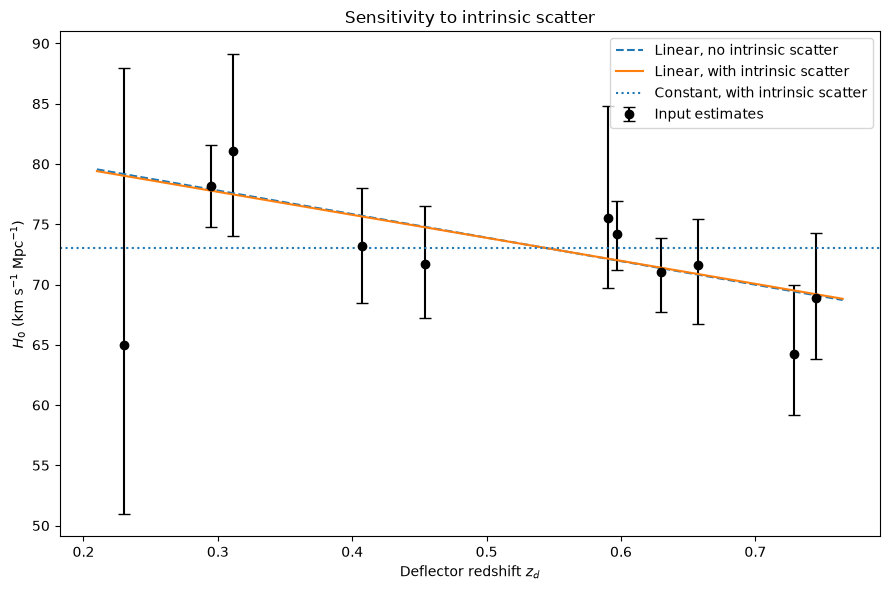

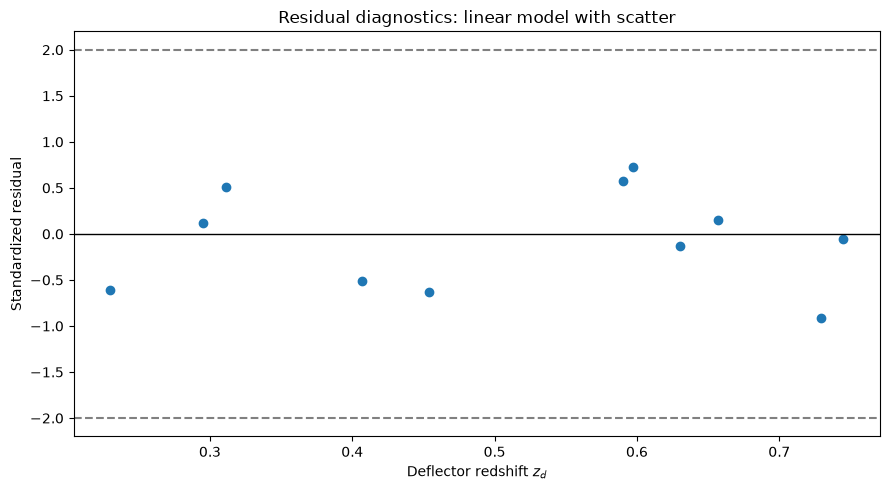

In [3]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

# ============================================================
# NEXT STAGE: TEST FOR INTRINSIC SCATTER
# ============================================================
# Run this after defining z, H0, sigma_minus, sigma_plus.
#
# Models:
#   1. Constant H0, no intrinsic scatter
#   2. Linear H0(z), no intrinsic scatter
#   3. Constant H0, with intrinsic scatter
#   4. Linear H0(z), with intrinsic scatter
#
# Intrinsic scatter is added in quadrature to each asymmetric
# measurement uncertainty.
#
# This is an exploratory model comparison, not a replacement
# for the full hierarchical lensing analysis.
# ============================================================

n = len(z)
z_ref = np.mean(z)
x = z - z_ref


# ------------------------------------------------------------
# 1. Negative log-likelihood with optional intrinsic scatter
# ------------------------------------------------------------

def nll_intrinsic(theta, model="linear", include_scatter=True):

    if model == "linear":
        h_ref, slope = theta[:2]
        prediction = h_ref + slope * x

        if include_scatter:
            s_int = theta[2]
        else:
            s_int = 0.0

    elif model == "constant":
        prediction = np.full(n, theta[0])

        if include_scatter:
            s_int = theta[1]
        else:
            s_int = 0.0

    else:
        raise ValueError("model must be 'linear' or 'constant'")

    # Effective uncertainties combine measurement error and
    # intrinsic scatter in quadrature.
    sm_eff = np.sqrt(sigma_minus**2 + s_int**2)
    sp_eff = np.sqrt(sigma_plus**2 + s_int**2)

    residual = H0 - prediction

    # Positive residual: use lower-side uncertainty.
    # Negative residual: use upper-side uncertainty.
    sigma_eff = np.where(
        residual >= 0,
        sm_eff,
        sp_eff
    )

    terms = (
        0.5 * (residual / sigma_eff)**2
        + np.log(sm_eff + sp_eff)
        - 0.5 * np.log(2.0 / np.pi)
    )

    return float(np.sum(terms))


# ------------------------------------------------------------
# 2. Fit each model with bounded optimization
# ------------------------------------------------------------

def fit_intrinsic_model(model, include_scatter):

    if model == "linear":
        if include_scatter:
            x0 = [np.mean(H0), 0.0, 2.0]
            bounds = [
                (20.0, 140.0),
                (-200.0, 200.0),
                (0.0, 50.0)
            ]
        else:
            x0 = [np.mean(H0), 0.0]
            bounds = [
                (20.0, 140.0),
                (-200.0, 200.0)
            ]

    else:
        if include_scatter:
            x0 = [np.mean(H0), 2.0]
            bounds = [
                (20.0, 140.0),
                (0.0, 50.0)
            ]
        else:
            x0 = [np.mean(H0)]
            bounds = [(20.0, 140.0)]

    result = minimize(
        nll_intrinsic,
        x0=np.array(x0, dtype=float),
        args=(model, include_scatter),
        method="Powell",
        bounds=bounds,
        options={
            "maxiter": 100000,
            "xtol": 1e-9,
            "ftol": 1e-9
        }
    )

    if not result.success:
        print(
            f"Warning: {model}, scatter={include_scatter}: "
            f"{result.message}"
        )

    if not np.isfinite(result.fun):
        raise RuntimeError(
            f"Invalid likelihood for {model}, "
            f"scatter={include_scatter}"
        )

    return result


fit_const_no_scatter = fit_intrinsic_model(
    "constant", False
)

fit_linear_no_scatter = fit_intrinsic_model(
    "linear", False
)

fit_const_scatter = fit_intrinsic_model(
    "constant", True
)

fit_linear_scatter = fit_intrinsic_model(
    "linear", True
)


# ------------------------------------------------------------
# 3. AIC and AICc
# ------------------------------------------------------------

def aic_aicc(nll_value, k, n_data):

    aic = 2 * k + 2 * nll_value

    if n_data <= k + 1:
        aicc = np.inf
    else:
        aicc = aic + 2 * k * (k + 1) / (n_data - k - 1)

    return aic, aicc


models = [
    ("Constant, no scatter", fit_const_no_scatter, 1),
    ("Linear, no scatter", fit_linear_no_scatter, 2),
    ("Constant, with scatter", fit_const_scatter, 2),
    ("Linear, with scatter", fit_linear_scatter, 3)
]

results = []

for name, fit, k in models:

    aic, aicc = aic_aicc(fit.fun, k, n)

    results.append({
        "name": name,
        "fit": fit,
        "k": k,
        "nll": fit.fun,
        "aic": aic,
        "aicc": aicc
    })


best_aicc = min(item["aicc"] for item in results)

print("=" * 72)
print("MODEL COMPARISON: INTRINSIC SCATTER")
print("=" * 72)

for item in results:

    print()
    print(item["name"])
    print(f"  NLL  = {item['nll']:.3f}")
    print(f"  AIC  = {item['aic']:.3f}")
    print(f"  AICc = {item['aicc']:.3f}")
    print(f"  Delta AICc from best = {item['aicc'] - best_aicc:.3f}")

print()
print("Lower AICc is preferred, but small differences are inconclusive.")


# ------------------------------------------------------------
# 4. Summarize the fitted parameters
# ------------------------------------------------------------

h_const_0 = fit_const_no_scatter.x[0]

h_linear_0, slope_0 = fit_linear_no_scatter.x
intercept_0 = h_linear_0 - slope_0 * z_ref

h_const_s, scatter_const = fit_const_scatter.x

h_linear_s, slope_s, scatter_linear = fit_linear_scatter.x
intercept_s = h_linear_s - slope_s * z_ref

print()
print("=" * 72)
print("FITTED PARAMETERS")
print("=" * 72)

print("Constant model, no intrinsic scatter:")
print(f"  H0 = {h_const_0:.3f} km/s/Mpc")

print()
print("Linear model, no intrinsic scatter:")
print(f"  H0 = {intercept_0:.3f} + ({slope_0:.3f}) z")
print(f"  Slope = {slope_0:.3f} km/s/Mpc per unit redshift")

print()
print("Constant model, with intrinsic scatter:")
print(f"  H0 = {h_const_s:.3f} km/s/Mpc")
print(f"  Intrinsic scatter = {scatter_const:.3f} km/s/Mpc")

print()
print("Linear model, with intrinsic scatter:")
print(f"  H0 = {intercept_s:.3f} + ({slope_s:.3f}) z")
print(f"  Slope = {slope_s:.3f} km/s/Mpc per unit redshift")
print(f"  Intrinsic scatter = {scatter_linear:.3f} km/s/Mpc")


# ------------------------------------------------------------
# 5. Residual diagnostics
# ------------------------------------------------------------

prediction_linear = h_linear_s + slope_s * x
residual_linear = H0 - prediction_linear

sm_eff = np.sqrt(sigma_minus**2 + scatter_linear**2)
sp_eff = np.sqrt(sigma_plus**2 + scatter_linear**2)

sigma_resid = np.where(
    residual_linear >= 0,
    sm_eff,
    sp_eff
)

standardized_residual = residual_linear / sigma_resid

print()
print("=" * 72)
print("RESIDUAL DIAGNOSTICS: LINEAR MODEL WITH SCATTER")
print("=" * 72)

for i in range(n):
    print(
        f"z={z[i]:.3f}, "
        f"residual={residual_linear[i]:+.2f}, "
        f"standardized residual={standardized_residual[i]:+.2f}"
    )

print()
print(
    "Largest absolute standardized residual = "
    f"{np.max(np.abs(standardized_residual)):.2f}"
)


# ------------------------------------------------------------
# 6. Plot fitted models
# ------------------------------------------------------------

z_plot = np.linspace(z.min() - 0.02, z.max() + 0.02, 300)
x_plot = z_plot - z_ref

plt.figure(figsize=(9, 6))

plt.errorbar(
    z,
    H0,
    yerr=[sigma_minus, sigma_plus],
    fmt="o",
    capsize=4,
    color="black",
    label="Input estimates"
)

plt.plot(
    z_plot,
    h_linear_0 + slope_0 * x_plot,
    linestyle="--",
    label="Linear, no intrinsic scatter"
)

plt.plot(
    z_plot,
    h_linear_s + slope_s * x_plot,
    label="Linear, with intrinsic scatter"
)

plt.axhline(
    h_const_s,
    linestyle=":",
    label="Constant, with intrinsic scatter"
)

plt.xlabel(r"Deflector redshift $z_d$")
plt.ylabel(r"$H_0$ (km s$^{-1}$ Mpc$^{-1}$)")
plt.title("Sensitivity to intrinsic scatter")
plt.legend()
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 7. Plot standardized residuals
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

plt.axhline(0, color="black", linewidth=1)
plt.axhline(2, linestyle="--", color="gray")
plt.axhline(-2, linestyle="--", color="gray")

plt.scatter(z, standardized_residual)

plt.xlabel(r"Deflector redshift $z_d$")
plt.ylabel("Standardized residual")
plt.title("Residual diagnostics: linear model with scatter")
plt.tight_layout()
plt.show()


SLOPE AND MODEL-COMPARISON CHECK
Linear intercept: 83.6530 km/s/Mpc
Linear slope: -19.5256 km/s/Mpc per unit redshift
Constant H0: 73.0317 km/s/Mpc
Observed 2*Delta log likelihood: 4.6247

NOMINAL 95% PROFILE-LIKELIHOOD INTERVAL
Slope interval: [-37.4244, -1.7189]
This is an approximate likelihood-ratio interval, not a Bayesian credible interval.

PARAMETRIC BOOTSTRAP
Simulations: 2000
Observed likelihood improvement: 4.6247
Bootstrap tail fraction: 0.0320
Under the assumed null simulation, fewer than about 5% of simulations produced an improvement this large.


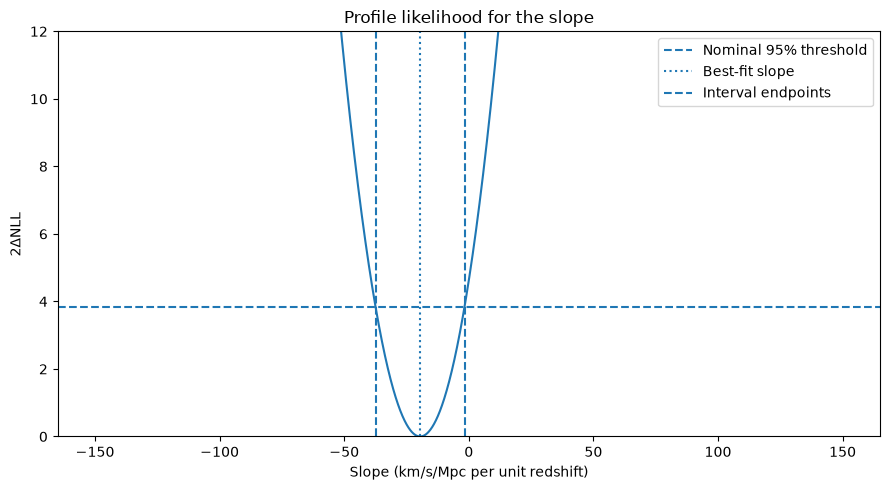

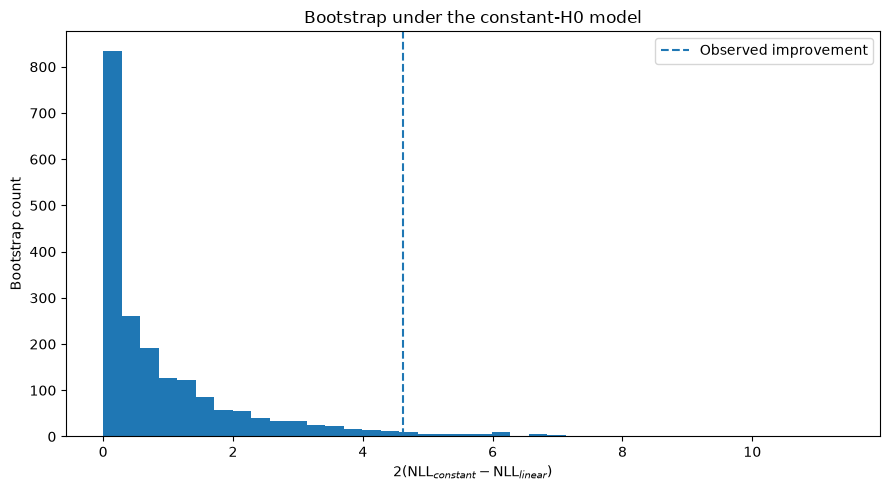

In [4]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize, minimize_scalar, brentq
from scipy.stats import chi2

# ============================================================
# SLOPE UNCERTAINTY AND PARAMETRIC BOOTSTRAP
# Uses the 11 existing measurements and asymmetric uncertainties.
# Intrinsic scatter is fixed to zero in this stage.
# ============================================================

z = np.asarray(z, dtype=float)
H0 = np.asarray(H0, dtype=float)
sigma_minus = np.asarray(sigma_minus, dtype=float)
sigma_plus = np.asarray(sigma_plus, dtype=float)

n = len(z)
z_ref = np.mean(z)
x = z - z_ref


# ------------------------------------------------------------
# 1. Correct split-normal negative log-likelihood
# ------------------------------------------------------------

def split_normal_nll(theta, model, y):

    if model == "constant":
        prediction = np.full(n, theta[0])

    elif model == "linear":
        h_ref, slope = theta
        prediction = h_ref + slope * x

    else:
        raise ValueError("Unknown model")

    residual = y - prediction

    # Observed value above prediction: use lower uncertainty.
    sigma = np.where(
        residual >= 0,
        sigma_minus,
        sigma_plus
    )

    terms = (
        0.5 * (residual / sigma)**2
        + np.log(sigma_minus + sigma_plus)
        - 0.5 * np.log(2.0 / np.pi)
    )

    return float(np.sum(terms))


# ------------------------------------------------------------
# 2. Fit constant and linear models
# ------------------------------------------------------------

def fit_split_model(y, model):

    if model == "constant":
        starts = [[70.0], [75.0], [80.0]]
    else:
        starts = [
            [73.0, 0.0],
            [80.0, -20.0],
            [65.0, 20.0]
        ]

    fits = []

    for start in starts:
        result = minimize(
            split_normal_nll,
            x0=np.asarray(start, dtype=float),
            args=(model, y),
            method="Nelder-Mead",
            options={
                "maxiter": 100000,
                "xatol": 1e-9,
                "fatol": 1e-9
            }
        )

        if result.success and np.isfinite(result.fun):
            fits.append(result)

    if not fits:
        raise RuntimeError(f"All {model} fits failed.")

    return min(fits, key=lambda fit: fit.fun)


fit_c = fit_split_model(H0, "constant")
fit_l = fit_split_model(H0, "linear")

observed_improvement = 2.0 * (fit_c.fun - fit_l.fun)

h_ref_fit, slope_fit = fit_l.x
intercept_fit = h_ref_fit - slope_fit * z_ref

print("=" * 65)
print("SLOPE AND MODEL-COMPARISON CHECK")
print("=" * 65)

print(f"Linear intercept: {intercept_fit:.4f} km/s/Mpc")
print(f"Linear slope: {slope_fit:.4f} km/s/Mpc per unit redshift")
print(f"Constant H0: {fit_c.x[0]:.4f} km/s/Mpc")
print(f"Observed 2*Delta log likelihood: {observed_improvement:.4f}")


# ------------------------------------------------------------
# 3. Profile-likelihood interval for the slope
# ------------------------------------------------------------

def profile_nll(slope_value):

    result = minimize_scalar(
        lambda h: split_normal_nll(
            [h, slope_value], "linear", H0
        ),
        bounds=(20.0, 140.0),
        method="bounded",
        options={"xatol": 1e-10}
    )

    if not result.success:
        raise RuntimeError("Profile optimization failed.")

    return result.fun


threshold = fit_l.fun + 0.5 * chi2.ppf(0.95, df=1)

slope_grid = np.linspace(-150.0, 150.0, 6001)
profile_values = np.array([
    profile_nll(s) for s in slope_grid
])

inside = profile_values <= threshold
best_idx = np.argmin(profile_values)

left_idx = best_idx
while left_idx > 0 and inside[left_idx - 1]:
    left_idx -= 1

right_idx = best_idx
while (
    right_idx < len(slope_grid) - 1
    and inside[right_idx + 1]
):
    right_idx += 1

if left_idx == 0 or right_idx == len(slope_grid) - 1:
    slope_low = np.nan
    slope_high = np.nan
    print("WARNING: Expand slope_grid to find both interval endpoints.")
else:
    slope_low = brentq(
        lambda s: profile_nll(s) - threshold,
        slope_grid[left_idx - 1],
        slope_grid[left_idx]
    )

    slope_high = brentq(
        lambda s: profile_nll(s) - threshold,
        slope_grid[right_idx],
        slope_grid[right_idx + 1]
    )

print()
print("NOMINAL 95% PROFILE-LIKELIHOOD INTERVAL")

if np.isfinite(slope_low) and np.isfinite(slope_high):
    print(f"Slope interval: [{slope_low:.4f}, {slope_high:.4f}]")
else:
    print("Interval could not be bounded on the chosen grid.")

print(
    "This is an approximate likelihood-ratio interval, "
    "not a Bayesian credible interval."
)


# ------------------------------------------------------------
# 4. Parametric bootstrap under the constant model
# ------------------------------------------------------------
# Simulate measurements from the fitted constant model using
# the split-normal measurement-error distribution.
#
# Under this null model, the central value is the same for
# every lens. The reported asymmetric error scales are retained.
# ------------------------------------------------------------

def draw_split_normal(center, rng):

    choose_minus = (
        rng.random(n)
        < sigma_minus / (sigma_minus + sigma_plus)
    )

    magnitude = np.abs(rng.normal(size=n))
    simulated = np.empty(n)

    simulated[choose_minus] = (
        center[choose_minus]
        - sigma_minus[choose_minus] * magnitude[choose_minus]
    )

    simulated[~choose_minus] = (
        center[~choose_minus]
        + sigma_plus[~choose_minus] * magnitude[~choose_minus]
    )

    return simulated


B = 2000
rng = np.random.default_rng(20261024)

null_center = np.full(n, fit_c.x[0])
bootstrap_improvement = np.empty(B)

for j in range(B):

    simulated_y = draw_split_normal(null_center, rng)

    simulated_c = fit_split_model(simulated_y, "constant")
    simulated_l = fit_split_model(simulated_y, "linear")

    bootstrap_improvement[j] = 2.0 * (
        simulated_c.fun - simulated_l.fun
    )

bootstrap_p = (
    1 + np.sum(bootstrap_improvement >= observed_improvement)
) / (B + 1)

print()
print("PARAMETRIC BOOTSTRAP")
print(f"Simulations: {B}")
print(f"Observed likelihood improvement: {observed_improvement:.4f}")
print(f"Bootstrap tail fraction: {bootstrap_p:.4f}")

if bootstrap_p < 0.05:
    print(
        "Under the assumed null simulation, fewer than about 5% "
        "of simulations produced an improvement this large."
    )
else:
    print(
        "The bootstrap does not show a likelihood improvement "
        "that is unusual at the conventional 5% level."
    )


# ------------------------------------------------------------
# 5. Plot profile likelihood and bootstrap distribution
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))
plt.plot(slope_grid, 2.0 * (profile_values - fit_l.fun))
plt.axhline(
    chi2.ppf(0.95, df=1),
    linestyle="--",
    label="Nominal 95% threshold"
)
plt.axvline(
    slope_fit,
    linestyle=":",
    label="Best-fit slope"
)

if np.isfinite(slope_low) and np.isfinite(slope_high):
    plt.axvline(slope_low, linestyle="--", label="Interval endpoints")
    plt.axvline(slope_high, linestyle="--")

plt.xlabel("Slope (km/s/Mpc per unit redshift)")
plt.ylabel(r"$2\Delta\mathrm{NLL}$")
plt.title("Profile likelihood for the slope")
plt.ylim(0, 12)
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 5))
plt.hist(bootstrap_improvement, bins=40)
plt.axvline(
    observed_improvement,
    linestyle="--",
    label="Observed improvement"
)
plt.xlabel(r"$2(\mathrm{NLL}_{constant}-\mathrm{NLL}_{linear})$")
plt.ylabel("Bootstrap count")
plt.title("Bootstrap under the constant-H0 model")
plt.legend()
plt.tight_layout()
plt.show()


In [5]:

import numpy as np
import pandas as pd
from scipy.optimize import minimize

# ============================================================
# NEXT STAGE: INFLUENCE ANALYSIS AND SOURCE AUDIT
# ============================================================

n = len(z)
z_ref = np.mean(z)
x = z - z_ref

# Lens labels in the same order as the input arrays.
# Verify these identifications against the papers before publication.
lens_names = [
    "WGD 2038-4008",
    "RXJ 1131-1231",
    "PG 1115+080",
    "SDSS J1433+6007",
    "HE 0435-1223",
    "J1537-3010",
    "DES J0408-5354",
    "B1608+656",
    "WFI 2033-4723",
    "HE 1104-1805",
    "SDSS J1206+4332"
]

# ------------------------------------------------------------
# 1. Split-normal likelihood, with optional mask
# ------------------------------------------------------------

def audit_nll(theta, mask=None):

    h_ref, slope = theta
    prediction = h_ref + slope * x
    residual = H0 - prediction

    sigma = np.where(
        residual >= 0,
        sigma_minus,
        sigma_plus
    )

    terms = (
        0.5 * (residual / sigma)**2
        + np.log(sigma_minus + sigma_plus)
        - 0.5 * np.log(2.0 / np.pi)
    )

    if mask is not None:
        terms = terms[mask]

    return float(np.sum(terms))


def fit_slope(mask=None, start=None):

    if start is None:
        start = [np.mean(H0), 0.0]

    result = minimize(
        audit_nll,
        x0=np.asarray(start, dtype=float),
        args=(mask,),
        method="Nelder-Mead",
        options={
            "maxiter": 100000,
            "xatol": 1e-9,
            "fatol": 1e-9
        }
    )

    if not result.success:
        raise RuntimeError(result.message)

    return result


# ------------------------------------------------------------
# 2. Full-sample fit
# ------------------------------------------------------------

full_fit = fit_slope()
h_ref_full, slope_full = full_fit.x
intercept_full = h_ref_full - slope_full * z_ref

print("=" * 68)
print("INFLUENCE ANALYSIS")
print("=" * 68)

print(f"Full-sample slope: {slope_full:.4f}")
print(f"Full-sample intercept: {intercept_full:.4f}")
print()

# ------------------------------------------------------------
# 3. Leave-one-lens-out slope analysis
# ------------------------------------------------------------

loo_rows = []

for i in range(n):

    mask = np.ones(n, dtype=bool)
    mask[i] = False

    fit = fit_slope(mask=mask, start=full_fit.x)

    slope_loo = fit.x[1]

    loo_rows.append({
        "Lens": lens_names[i],
        "z_d": z[i],
        "H0": H0[i],
        "sigma_minus": sigma_minus[i],
        "sigma_plus": sigma_plus[i],
        "Slope_without_lens": slope_loo,
        "Change_from_full_slope": slope_loo - slope_full,
        "Absolute_slope_change": abs(slope_loo - slope_full)
    })

loo_df = pd.DataFrame(loo_rows)
loo_df = loo_df.sort_values(
    "Absolute_slope_change",
    ascending=False
).reset_index(drop=True)

print("Most influential points by absolute slope change:")
print(
    loo_df[
        [
            "Lens",
            "z_d",
            "Slope_without_lens",
            "Change_from_full_slope"
        ]
    ].to_string(index=False, float_format=lambda value: f"{value:.3f}")
)

print()
print(
    "Leave-one-out slope range: "
    f"{loo_df['Slope_without_lens'].min():.3f} to "
    f"{loo_df['Slope_without_lens'].max():.3f}"
)

print()
print("Number of leave-one-out slopes retaining a negative sign:",
      int(np.sum(loo_df["Slope_without_lens"] < 0)),
      "out of", n)

# ------------------------------------------------------------
# 4. Build a source-audit template
# ------------------------------------------------------------
# Fill in source paper, table/figure, exact measurement definition,
# and modelling assumptions only after checking the original papers.
# Do not treat a blank field as a verified source.
# ------------------------------------------------------------

source_audit = pd.DataFrame({
    "Lens": lens_names,
    "z_d_used": z,
    "H0_used": H0,
    "sigma_minus_used": sigma_minus,
    "sigma_plus_used": sigma_plus,
    "Source_paper": ["UNVERIFIED"] * n,
    "Table_or_figure": ["CHECK ORIGINAL PAPER"] * n,
    "H0_definition_and_units": ["CHECK ORIGINAL PAPER"] * n,
    "Cosmological_assumptions": ["CHECK ORIGINAL PAPER"] * n,
    "Lens_model_and_kinematics": ["CHECK ORIGINAL PAPER"] * n,
    "External_data_or_priors": ["CHECK ORIGINAL PAPER"] * n,
    "Covariance_or_shared_systematics": ["CHECK ORIGINAL PAPER"] * n,
    "Verified": [False] * n
})

print()
print("=" * 68)
print("SOURCE AUDIT TEMPLATE")
print("=" * 68)
print(source_audit.to_string(index=False))

# Export files so they can be filled in and checked.
loo_df.to_csv("tdcosmo_leave_one_out.csv", index=False)
source_audit.to_csv("tdcosmo_source_audit_template.csv", index=False)

print()
print("Saved:")
print("  tdcosmo_leave_one_out.csv")
print("  tdcosmo_source_audit_template.csv")

# ------------------------------------------------------------
# 5. Plot leave-one-out slopes
# ------------------------------------------------------------

plot_df = loo_df.sort_values("Slope_without_lens")

plt.figure(figsize=(10, 6))

plt.axvline(
    slope_full,
    linestyle="--",
    color="black",
    label="Full-sample slope"
)

plt.scatter(
    plot_df["Slope_without_lens"],
    plot_df["Lens"]
)

plt.xlabel("Slope after removing one lens")
plt.ylabel("Excluded lens")
plt.title("Influence of individual lenses on the fitted slope")
plt.legend()
plt.tight_layout()
plt.show()


ModuleNotFoundError: No module named 'pandas'